<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 5.4 - Gradient Descent II</h2>
<p>The previous lecture used every observation for each gradient. This notebook retains the stochastic tips demonstration and adds controlled comparisons of batch size, gradient noise and starting points.</p><p>Central question: what changes when each parameter update uses only part of the data?</p><p>After this notebook, you should distinguish an update from an epoch, calculate a stochastic gradient, compare batch sizes using a stated work budget, and explain the limits of local optimization.</p>
<a id="lecture-structure"></a><h3>Lecture Structure</h3><ol><li><a href="#section1">Import Tips Data</a></li><li><a href="#section2">Stochastic Gradient Descent</a></li></ol>
<p><a href="#lecture-summary">Lecture summary</a></p>
<h3>Optional extensions</h3><ol start="3"><li><a href="#section3">Compare batch sizes on sensor data</a></li><li><a href="#section4">Gradient noise and a decaying learning rate</a></li><li><a href="#section5">Starting points and convexity</a></li></ol>
<p>Run Setup Notebook first, then run the sections in order. The main section numbers match the slide handoffs.</p>
<h3>Sources and documentation</h3><p><a href="../slides/week5_lecture4.pptx">Lecture slides</a> | <a href="DATA_SOURCES.html">Dataset sources and fields</a> | <a href="https://numpy.org/doc/stable/reference/generated/numpy.mean.html">NumPy means</a> | <a href="https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html">Notebook sliders</a></p>

<h2>Setup Notebook</h2><p>The course environment supplies NumPy, pandas, Matplotlib and Seaborn, plus ipywidgets for the sliders. All datasets are local. Plot layouts live in <a href="utils.py">utils.py</a>. Loss functions, gradients, parameter updates and optimization loops remain visible below.</p>

In [1]:
import numpy as np
import pandas as pd
from ipywidgets import interact, fixed, IntSlider

import utils

%matplotlib inline
RANDOM_STATE = 538
utils.configure_plots()
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_rows', 10)

<a id="Import-Tips-Data"></a>
<a id="section1"></a><h2>1. Import Tips Data</h2><p>Question: what does one restaurant bill tell us about tip percentages?</p>

<h3>Load the same classroom sample</h3><p>The local tips table contains one row per restaurant bill. Keep the first 243 rows, matching the existing slide examples. This sample describes one restaurant context rather than all restaurant customers.</p>

In [2]:
tips = pd.read_csv('tips.csv').iloc[:-1].copy()
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<h3>Calculate the response</h3><p>Divide the tip by the bill and multiply by 100. A constant model predicts the same percentage for every bill.</p>

In [3]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
tips[['total_bill', 'tip', 'tip_pct']].head()

,total_bill,tip,tip_pct
0,16.99,1.01,5.944673
1,10.34,1.66,16.054159
2,21.01,3.50,16.658734
3,23.68,3.31,13.978041
4,24.59,3.61,14.680765


<h3>Inspect the same tips sample</h3><p>The distribution matches the preceding notebooks. The model below predicts tip amount from bill amount, then standardizes both variables for the original stochastic demonstration.</p>

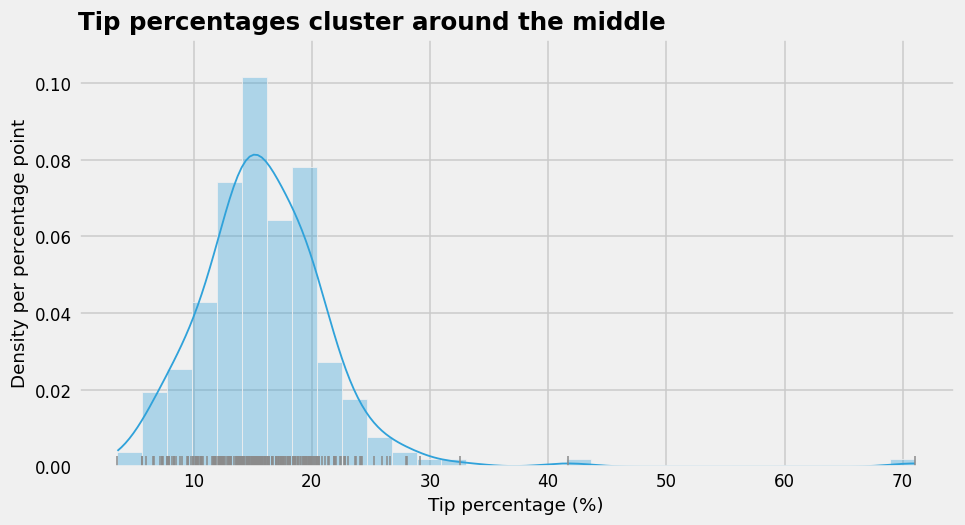

In [4]:
utils.plot_tips(tips['tip_pct'])

<p>Takeaway: The data and response definition determine the loss. Keep them fixed when comparing optimization methods.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Stochastic-Gradient-Descent"></a>
<a id="section2"></a><h2>2. Stochastic Gradient Descent</h2><p>Question: how does using one observation at a time affect the update path?</p>

<h3>Write the single-observation gradient</h3><p>The prediction retains an intercept and slope. The loss function also accepts arrays for monitoring the whole sample. The gradient below deliberately uses one observation for each update.</p>

In [5]:
def mse(theta0, theta1, x, y_obs):
    y_hat = theta0 + theta1 * x
    return np.mean((y_hat - y_obs)**2)

def grad_mse(theta0, theta1, x, y_obs):
    y_hat = theta0 + theta1 * x
    grad_0 = -2 * (y_obs - y_hat)
    grad_1 = -2 * x * (y_obs - y_hat)
    return grad_0, grad_1

<h3>Scale and shuffle the observations</h3><p>Expose the original scaling calculation. One epoch visits all 243 observations once in a shuffled order. A stochastic update uses one row, so 20 epochs contain 4,860 updates. Seed 538 fixes the order for reproducibility.</p>

In [6]:
x_raw = tips['total_bill'].to_numpy()
y_raw = tips['tip'].to_numpy()
x = (x_raw - x_raw.mean()) / x_raw.std()
y_obs = (y_raw - y_raw.mean()) / y_raw.std()
alpha = 0.02
num_epochs = 20
num_obs = len(tips)
num_steps = num_epochs * num_obs
order_rng = np.random.default_rng(RANDOM_STATE)
data_ids = np.concatenate([order_rng.permutation(num_obs) for _ in range(num_epochs)])
print(f'{num_obs} rows × {num_epochs} epochs = {num_steps} updates')

243 rows × 20 epochs = 4860 updates


<h3>Keep the stochastic update loop visible</h3><p>The loop calculates the gradient from the selected row and updates both parameters together. Record the selected-row loss before each update and the full-data loss at every parameter pair. These two quantities answer different questions.</p>

In [7]:
def trace_sgd(steps, data_ids, x, y_obs, alpha=0.02, start=(12.5, 7.5)):
    theta0, theta1 = start
    path = [(theta0, theta1)]
    full_losses = [mse(theta0, theta1, x, y_obs)]
    sampled_losses = []
    for row_id in data_ids[:steps]:
        sampled_losses.append(mse(theta0, theta1, x[row_id], y_obs[row_id]))
        gradient_0, gradient_1 = grad_mse(theta0, theta1, x[row_id], y_obs[row_id])
        new_theta0 = theta0 - alpha * gradient_0
        new_theta1 = theta1 - alpha * gradient_1
        theta0, theta1 = new_theta0, new_theta1
        path.append((theta0, theta1))
        full_losses.append(mse(theta0, theta1, x, y_obs))
    return np.array(path), np.array(full_losses), np.array(sampled_losses)

<h3>Inspect the fitted line and objective</h3><p>The slider retains the original range and learning rate. Release the slider to draw its selected step. The contours and surface use full-data MSE, and the path height uses the same full-data objective.</p>

In [8]:
def show_sgd(steps):
    path, full_losses, sampled_losses = trace_sgd(steps, data_ids, x, y_obs, alpha)
    utils.plot_line_path(path, full_losses, x, y_obs, mse,
                        scaled=True, sampled_losses=sampled_losses)

interact(show_sgd, steps=IntSlider(value=1, min=1, max=num_steps,
                                  continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='steps', max=4860, min=1), Outpu…

<p>The saved view below shows one complete epoch. The faint selected-row losses vary because each step uses a different observation. The blue curve monitors the same whole-data objective throughout.</p>

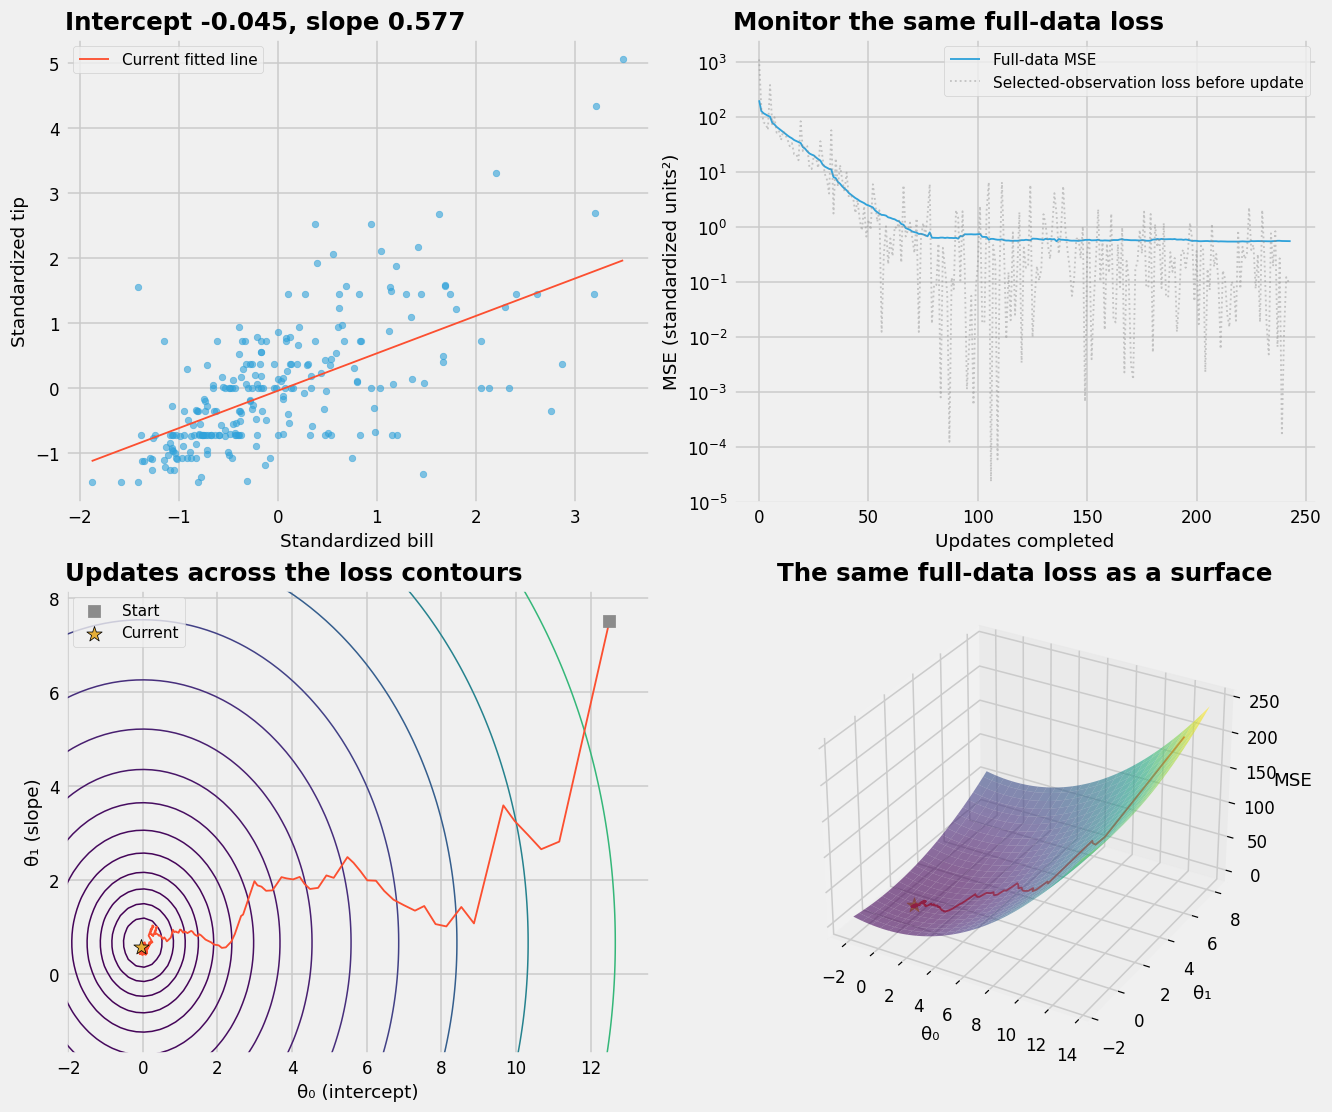

In [9]:
show_sgd(num_obs)

<h3>Read the completed run</h3><p>A fixed learning rate permits continued variation near the minimum. The final loss is one reproducible outcome for this ordering, rather than a guarantee for every shuffle.</p>

In [10]:
sgd_path, sgd_losses, sampled_losses = trace_sgd(num_steps, data_ids, x, y_obs, alpha)
print('Completed updates:', len(sgd_path)-1)
print('Initial full-data MSE:', round(sgd_losses[0], 4))
print('Final full-data MSE:', round(sgd_losses[-1], 4))
print('Final parameters:', sgd_path[-1].round(4))

Completed updates: 4860
Initial full-data MSE: 203.3637
Final full-data MSE: 0.7177
Final parameters: [0.2113 1.0359]


<p>Takeaway: A stochastic gradient uses one observation. Monitor the full-data objective separately from the changing one-observation losses.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="lecture-summary"></a><h2>Lecture summary</h2><ul><li>An update changes the parameters once. An epoch visits the dataset once.</li><li>A stochastic gradient uses one observation, while a full-batch gradient averages all rows.</li><li>Fixing the shuffle seed makes a comparison reproducible.</li><li>Single-row losses and full-data MSE are different quantities.</li><li>A fixed learning rate does not guarantee exact convergence of a stochastic run.</li></ul>

<a id="section3"></a><h2>3. Compare batch sizes on sensor data</h2><p>Optional extension.</p><p>Question: how do batch size and the comparison budget change the loss curves?</p>

<h3>Load a second fitting problem</h3><p>Reuse the 96 constructed sensor readings from Lecture 5.3. Standardize reference pressure and retain sensor readings in kPa. Each row is one constructed calibration condition. The comparison uses training loss only.</p>

In [11]:
calibration = pd.read_csv('illustrative_sensor_calibration.csv')
pressure = calibration['reference_kpa'].to_numpy()
reading = calibration['sensor_kpa'].to_numpy()
pressure_scaled = (pressure-pressure.mean()) / pressure.std()
calibration.head()

,reference_kpa,temperature_c,sensor_kpa
0,125.1007,30.0127,142.8188
1,211.6221,23.0572,233.1352
2,189.5266,15.8176,207.6651
3,20.6806,21.4629,30.1319
4,67.0114,33.7016,83.4898


<h3>Average gradients within a batch</h3><p>The prediction and MSE use the same formulas as before. Average the residual and residual-times-feature over whichever rows enter the batch.</p>

In [12]:
def batch_loss(theta, x, y):
    residual = theta[0] + theta[1] * x - y
    return np.mean(residual**2)

def batch_gradient(theta, x, y):
    residual = theta[0] + theta[1] * x - y
    return np.array([2 * residual.mean(), 2 * np.mean(residual * x)])

<h3>Expose the batch selection and update</h3><p>The outer loop shuffles once per epoch. The inner loop selects consecutive groups from the shuffled order and applies one gradient update per group. A decay of zero keeps the learning rate fixed. The loss evaluations are teaching diagnostics and are excluded from the gradient-work counts.</p>

In [13]:
def run_batches(x, y, batch_size, alpha=0.05, epochs=20, decay=0.0, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    theta = np.zeros(2)
    path = [theta.copy()]
    step_losses = [batch_loss(theta, x, y)]
    epoch_losses = [step_losses[0]]
    update = 0
    for epoch in range(epochs):
        order = rng.permutation(len(x))
        for start in range(0, len(x), batch_size):
            rows = order[start:start + batch_size]
            gradient = batch_gradient(theta, x[rows], y[rows])
            rate = alpha / (1 + decay * update)
            theta = theta - rate * gradient
            update += 1
            path.append(theta.copy())
            step_losses.append(batch_loss(theta, x, y))
        epoch_losses.append(step_losses[-1])
    return {'theta': theta, 'path': np.array(path),
            'step_loss': np.array(step_losses), 'epoch_loss': np.array(epoch_losses)}

<h3>Compare equal passes through the data</h3><p>Use identical data, starting predictions, rate and epoch count. Batch sizes 96, 16 and 1 give one, six and 96 updates per epoch. All use 96 observations in gradient calculations per epoch, but their update overhead differs.</p>

Full batch (96): 1 updates per epoch
Mini-batch (16): 6 updates per epoch
Stochastic (1): 96 updates per epoch


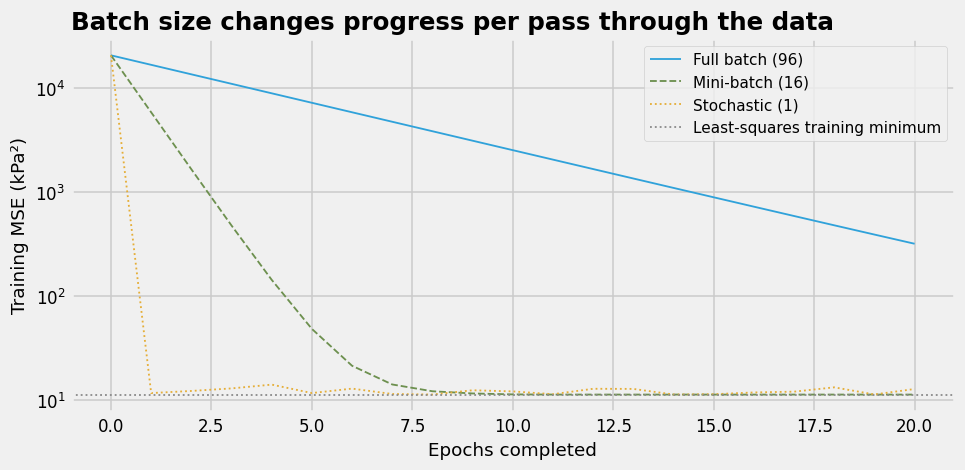

In [14]:
runs = {}
for name, size in [('Full batch (96)', 96), ('Mini-batch (16)', 16), ('Stochastic (1)', 1)]:
    runs[name] = run_batches(pressure_scaled, reading, batch_size=size)
    print(f'{name}: {int(np.ceil(len(reading)/size))} updates per epoch')
design = np.column_stack([np.ones(len(reading)), pressure_scaled])
optimum = np.linalg.lstsq(design, reading, rcond=None)[0]
minimum_loss = batch_loss(optimum, pressure_scaled, reading)
utils.plot_training_curves({name: run['epoch_loss'] for name, run in runs.items()},
    minimum_loss, 'Batch size changes progress per pass through the data', xlabel='Epochs completed')

<p>More frequent updates change the path within an epoch. The stochastic curve also varies because each row supplies a noisy gradient. This figure compares passes through the sample rather than elapsed time.</p>

<h3>Compare the update count</h3><p>Redraw the same runs against the number of updates. Equal update counts use different numbers of observations, so this axis answers a different work-budget question. The horizontal scale is logarithmic after the first update to separate early changes and display all runs.</p>

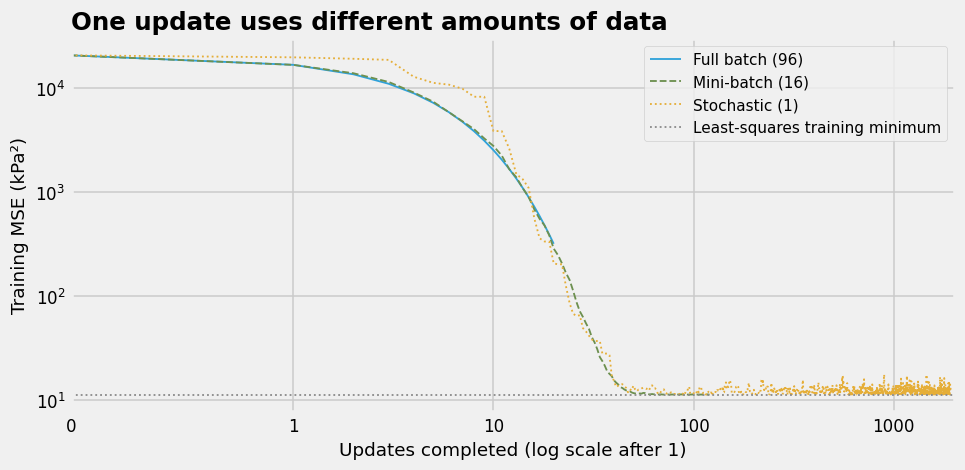

In [15]:
utils.plot_training_curves({name: run['step_loss'] for name, run in runs.items()},
    minimum_loss, 'One update uses different amounts of data', log_updates=True)

<p>Takeaway: State the comparison budget. Equal updates, equal epochs and equal elapsed time are distinct comparisons.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section4"></a><h2>4. Gradient noise and a decaying learning rate</h2><p>Optional extension.</p><p>Question: why do stochastic updates keep moving near the least-squares solution?</p>

<h3>Inspect gradients at the training minimum</h3><p>The average gradient is almost zero at the least-squares fit, but individual residuals remain. Draw 300 random batches of each size without replacement within each batch, and record the slope-gradient component.</p>

Full-data gradient: [0. 0.]


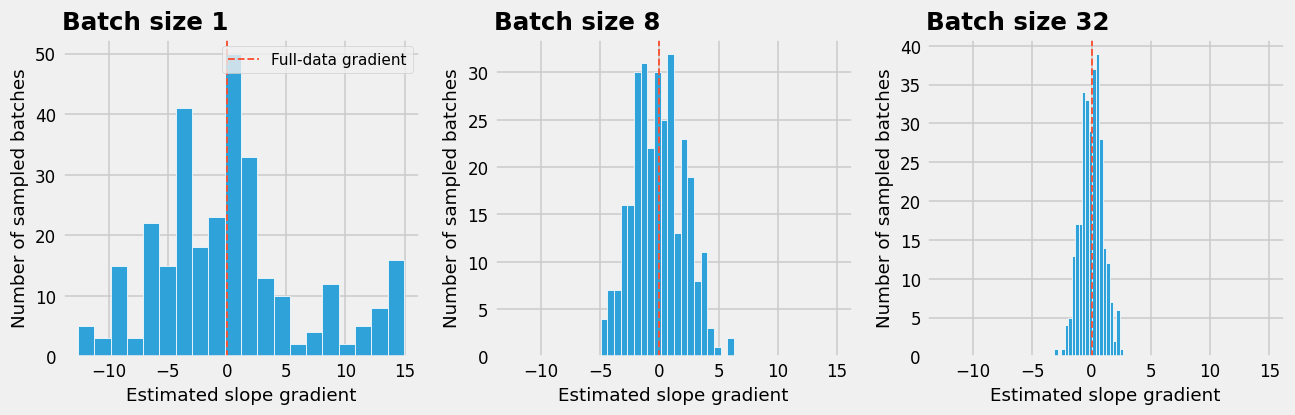

In [16]:
noise_rng = np.random.default_rng(RANDOM_STATE)
full_gradient = batch_gradient(optimum, pressure_scaled, reading)
estimates = {}
for size in [1, 8, 32]:
    slope_gradients = []
    for repeat in range(300):
        rows = noise_rng.choice(len(reading), size=size, replace=False)
        slope_gradients.append(batch_gradient(optimum, pressure_scaled[rows], reading[rows])[1])
    estimates[size] = np.array(slope_gradients)
print('Full-data gradient:', full_gradient.round(8))
utils.plot_gradient_noise(estimates, full_gradient[1])

<p>The distributions narrow as more observations enter a batch. Their spread comes from which rows were sampled. A nearly zero full-data gradient does not require every single-row gradient to be zero.</p>

<h3>Reduce the rate over updates</h3><p>Compare a fixed stochastic rate with <code>alpha / (1 + decay * update)</code>. Both runs use the same shuffled orders. The schedule reduces the magnitude of later noisy updates.</p>

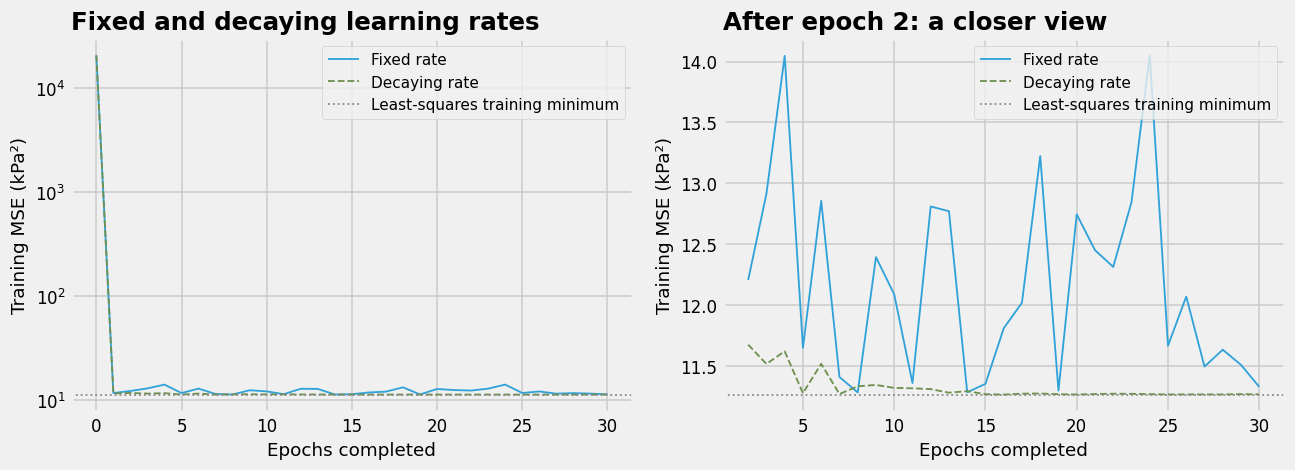

In [17]:
fixed_run = run_batches(pressure_scaled, reading, batch_size=1, epochs=30, decay=0)
decaying_run = run_batches(pressure_scaled, reading, batch_size=1, epochs=30, decay=0.005)
utils.plot_training_curves({'Fixed rate': fixed_run['epoch_loss'],
    'Decaying rate': decaying_run['epoch_loss']}, minimum_loss,
    'Fixed and decaying learning rates', xlabel='Epochs completed', zoom_after=2)

<p>The fixed rate continues to respond to each sampled gradient. The decaying rate reduces later changes in this run. An overly rapid decay would also slow useful progress, so a schedule still needs an appropriate scale.</p>

<p>Takeaway: Batch averaging reduces gradient variability. A declining learning rate reduces the parameter changes caused by the remaining variability.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section5"></a><h2>5. Starting points and convexity</h2><p>Optional extension.</p><p>Question: does a small gradient establish the best possible objective value?</p>

<h3>Define an objective with two minima</h3><p>The linear-model MSE above is convex in its parameters. With a full-rank design matrix, its minimizer is unique. Now use an explicit quartic objective with two minima to examine the limit of following local derivatives.</p>

In [18]:
def objective(w):
    return 0.05 * w**4 - 0.5 * w**2 + 0.2 * w

def derivative(w):
    return 0.2 * w**3 - w + 0.2

<h3>Keep the update loop unchanged</h3><p>Run the same rate and step count from minus three and plus three. Store every parameter so the two paths are visible.</p>

In [19]:
def descend_1d(start, alpha=0.1, steps=100):
    w = float(start)
    path = [w]
    for _ in range(steps):
        gradient = derivative(w)
        w = w - alpha * gradient
        path.append(w)
    return np.array(path)

paths = {start: descend_1d(start) for start in [-3.0, 3.0]}
for start, path in paths.items():
    print(f'Start {start:g}: final w {path[-1]:.4f}, objective {objective(path[-1]):.4f}')

Start -3: final w -2.3301, objective -1.7068
Start 3: final w 2.1284, objective -0.8133


<h3>Read the two paths and a chord</h3><p>For a convex function, every chord lies on or above the function over the interval between its endpoints. One chord passing below the curve disproves convexity. The right panel supplies such a counterexample for this quartic.</p>

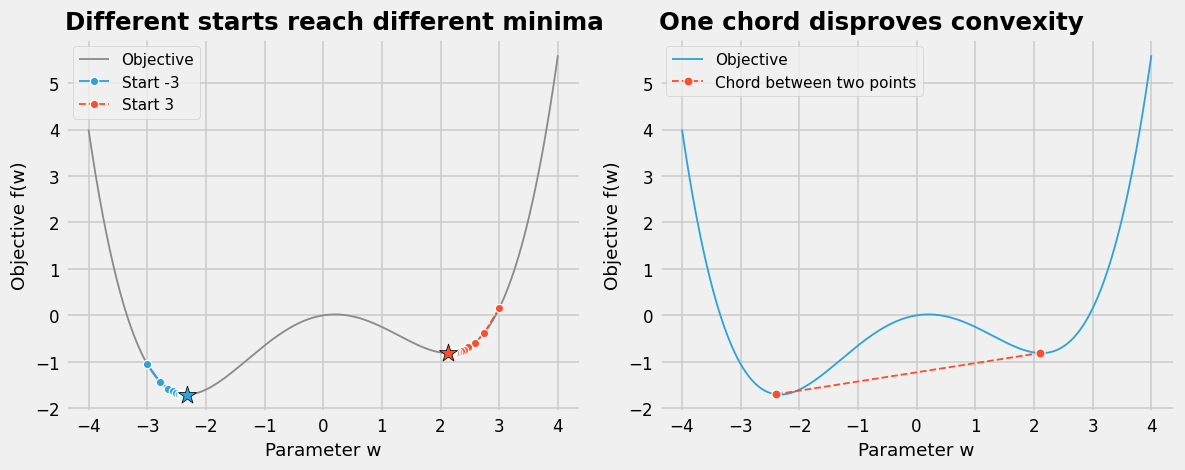

In [20]:
grid = np.linspace(-4, 4, 401)
endpoints = np.array([-2.4, 2.1])
utils.plot_nonconvex(grid, objective(grid), paths,
    {start: objective(path) for start, path in paths.items()},
    (endpoints, objective(endpoints)))

<p>The two starting values approach different minima, and one has a higher objective value. A small derivative at either endpoint does not identify which solution is globally best. Convexity rules out suboptimal local minima, but convergence still requires suitable optimization settings.</p>

<p>Takeaway: Gradient descent follows local information. The model-and-loss objective determines whether a local minimum is also global.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>